In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("beginner_eda_employees.csv")

In [3]:
df.head()

,employee_id,age,department,years_experience,salary
0,1,22.0,Sales,1,30000.0
1,2,25.0,HR,2,34000.0
2,3,28.0,IT,4,42000.0
3,4,31.0,IT,7,56000.0
4,5,35.0,Finance,12,72000.0


df.head() shows the first five rows

In [4]:
df.tail()

,employee_id,age,department,years_experience,salary
15,16,32.0,Finance,8,61000.0
16,17,28.0,HR,4,43000.0
17,18,50.0,IT,25,1500000.0
18,19,34.0,Sales,10,68000.0
19,20,NaN,Finance,11,NaN


df.tail() shows the last five rows.

df.shape tells us the number of rows and columns.

Expected result:

(20, 5)

We have 20 employees and 5 columns.

In [5]:
df.shape

(20, 5)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   employee_id       20 non-null     int64  
 1   age               19 non-null     float64
 2   department        20 non-null     object 
 3   years_experience  20 non-null     int64  
 4   salary            19 non-null     float64
dtypes: float64(2), int64(2), object(1)
memory usage: 932.0+ bytes


This tells us:

The names of our columns.

How many non-missing values each column has.

The data type of each column.

In [7]:
df.describe()

,employee_id,age,years_experience,salary
count,20.00000,19.000000,20.000000,1.900000e+01
mean,10.50000,32.368421,8.850000,1.348421e+05
std,5.91608,7.327350,6.892215,3.315471e+05
min,1.00000,22.000000,1.000000,3.000000e+04
25%,5.75000,27.500000,3.750000,4.000000e+04
50%,10.50000,31.000000,7.500000,5.600000e+04
75%,15.25000,36.000000,12.250000,7.700000e+04
max,20.00000,50.000000,25.000000,1.500000e+06


This gives us numerical summaries, including the mean, median, minimum, maximum, and quartiles.

Questions to ask:

What is the average age?

What is the minimum salary?

What is the maximum salary?

How many employees are included in the salary summary?

**Explore categorical data**

Our department column contains categories rather than numerical measurements.

Count employees in each department:

In [8]:
df["department"].value_counts()

department
IT         6
Sales      5
Finance    5
HR         4
Name: count, dtype: int64

Visualize the departments

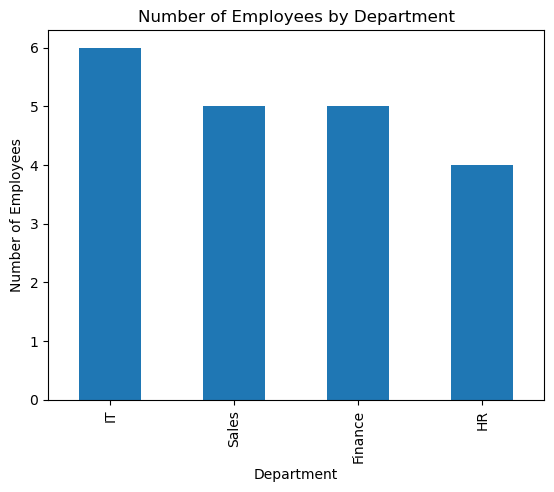

In [9]:
df["department"].value_counts().plot(kind="bar")

plt.title("Number of Employees by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")

plt.show()

**We are seeing how employees are distributed across departments**

**Check missing values**

In [10]:
df.isnull().sum()

employee_id         0
age                 1
department          0
years_experience    0
salary              1
dtype: int64

Now calculate the percentage:

In [11]:
df.isnull().mean() * 100

employee_id         0.0
age                 5.0
department          0.0
years_experience    0.0
salary              5.0
dtype: float64

This tells us what percentage of each column is missing.

Let's visualize them:

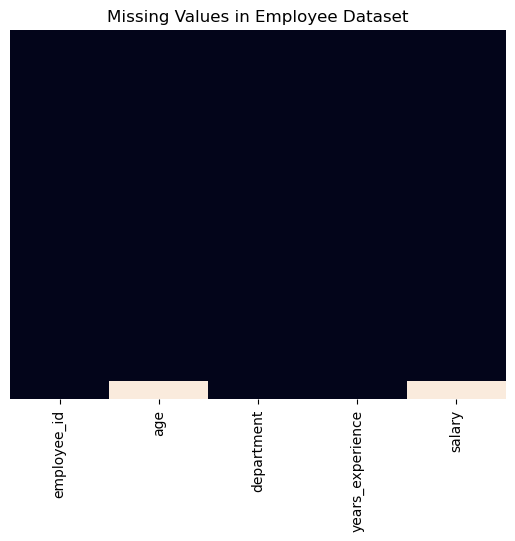

In [13]:
sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in Employee Dataset")
plt.show()

**Handling the missing values**

*fill the missing age with the median:*

In [18]:
df["age"] = df["age"].fillna(
    df["age"].median()
)

In [19]:
df["salary"] = df["salary"].fillna(
    df["salary"].median()
)

**Why median?**

*The median is less affected by extreme values than the mean. That is useful here because our salary column contains an unusually high value.*

In [20]:
df.isnull().sum()

employee_id         0
age                 0
department          0
years_experience    0
salary              0
dtype: int64

**Exlpore numerical distributions**

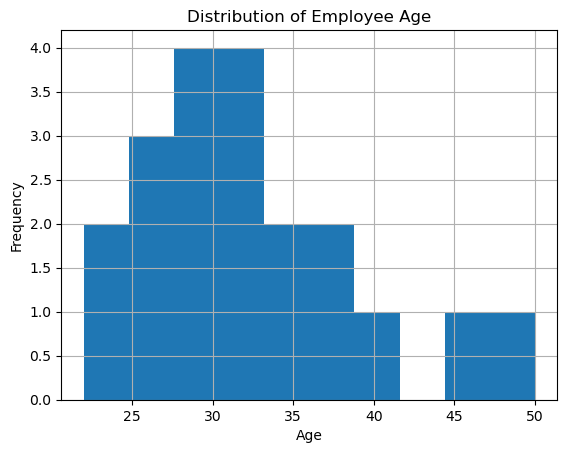

In [21]:
df["age"].hist(bins=10)

plt.title("Distribution of Employee Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

**Salary:**

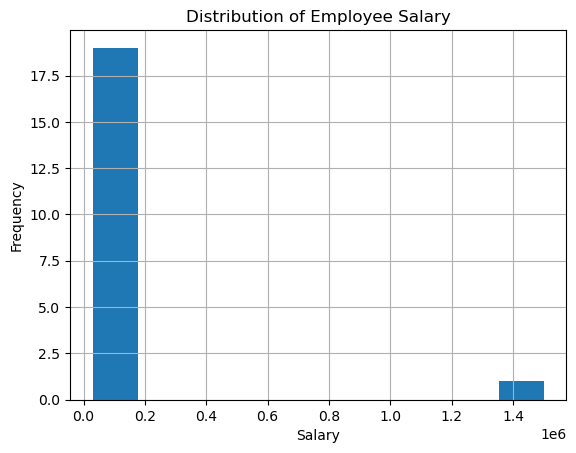

In [22]:
df["salary"].hist(bins=10)

plt.title("Distribution of Employee Salary")
plt.xlabel("Salary")
plt.ylabel("Frequency")

plt.show()

What does a histogram show?

The X-axis shows the values.

The Y-axis shows how many observations fall into each range.

The bars show the frequency of those values.

**Check skewness**

In [23]:
print("Age skewness:", df["age"].skew())

Age skewness: 0.9488373358813309


In [24]:
print("Salary skewness:", df["salary"].skew())

Salary skewness: 4.429702057579861


**General interpretation:**

Around zero: approximately symmetric.

Positive: right-skewed.

Negative: left-skewed.

Salary data should show strong positive skewness because of the unusually high salary.

**Find potential outliers using a boxplot**

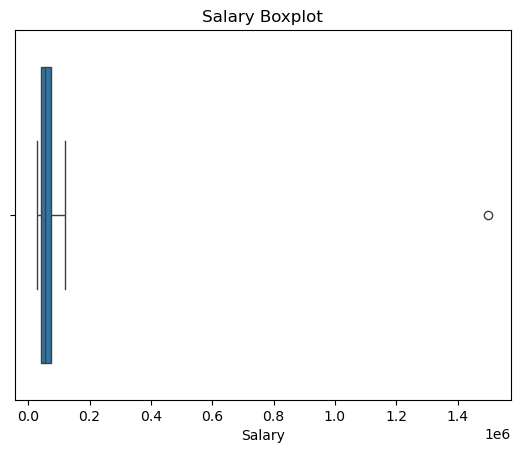

In [25]:
sns.boxplot(x=df["salary"])

plt.title("Salary Boxplot")
plt.xlabel("Salary")

plt.show()

The line inside the box is the median.

The box shows the middle 50% of values.

The whiskers extend to the most extreme values within the boxplot rule.

Dots beyond the whiskers are potential outliers.

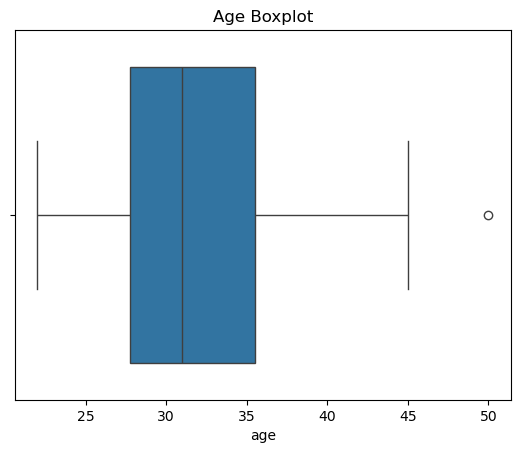

In [26]:
sns.boxplot(x=df["age"])

plt.title("Age Boxplot")
plt.show()

Compare the two plots.

Which variable appears to have a more extreme observation?

**Detect potential outliers using IQR**

*calculate the quartiles for salary*

In [29]:
Q1 = df["salary"].quantile(0.25)

Q3 = df["salary"].quantile(0.75)

IQR = Q3 - Q1

*Calculate the boundaries:*

In [30]:
lower_bound = Q1 - (1.5 * IQR)

upper_bound = Q3 + (1.5 * IQR)

In [31]:
print("Lower boundary:", lower_bound)

print("Upper boundary:", upper_bound)

Lower boundary: -9250.0
Upper boundary: 124750.0


**Find the observations outside those boundaries**

In [32]:
outliers = df[
    (df["salary"] < lower_bound) |
    (df["salary"] > upper_bound)
]

print(outliers)

    employee_id   age department  years_experience     salary
17           18  50.0         IT                25  1500000.0


*We are now identifying observations that are unusually far from the middle 50% of salaries.*

**Explore relationships between variables**

Investigate whether age and salary appear related:

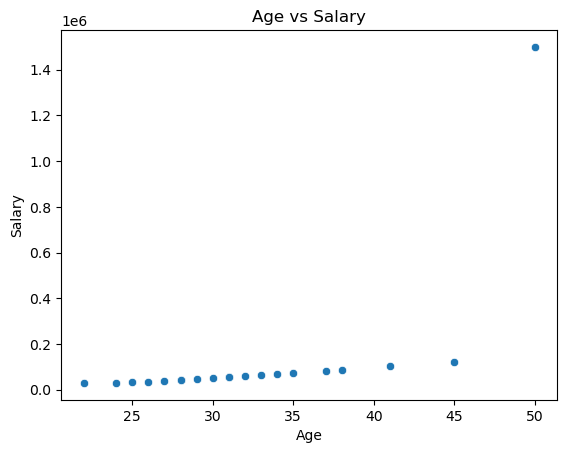

In [33]:
sns.scatterplot(
    data=df,
    x="age",
    y="salary"
)

plt.title("Age vs Salary")
plt.xlabel("Age")
plt.ylabel("Salary")

plt.show()

*Then, experience and salary:*

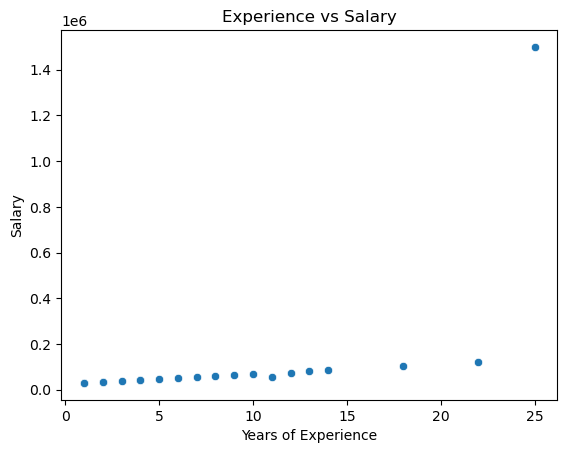

In [34]:
sns.scatterplot(
    data=df,
    x="years_experience",
    y="salary"
)

plt.title("Experience vs Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")

plt.show()

**Questions to ask:**

Does salary tend to increase with experience?

Does the relationship look approximately linear?

Is there an unusual point far away from the others?

These plots help us understand whether age and experience might be useful predictors of salary.

**Explore correlations**

In [35]:
correlation = df.corr(numeric_only=True)

print(correlation)

                  employee_id       age  years_experience    salary
employee_id          1.000000  0.408771          0.407242  0.316314
age                  0.408771  1.000000          0.987271  0.642962
years_experience     0.407242  0.987271          1.000000  0.612443
salary               0.316314  0.642962          0.612443  1.000000


Visualize the correlations:

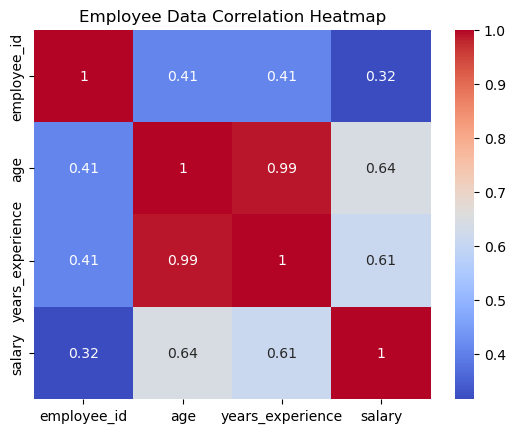

In [36]:
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Employee Data Correlation Heatmap")

plt.show()

Correlation ranges from -1 to +1:

Positive: the variables tend to increase together.

Negative: one tends to decrease as the other increases.

Around zero: little linear association.

**EDA Observations**

**Dataset overview:**

The dataset contains 20 employee observations and five columns. The variables include age, department, years of experience, and salary.

**Missing values:**

The original dataset contains missing values in age and salary. I identified these using isnull().sum().

**Distributions:**

I used histograms to explore the distributions of age and salary. Salary appears right-skewed due to an unusually high observation.

**Outliers:**

I used boxplots and the IQR method to identify potential salary outliers. These observations should be investigated before deciding whether to keep or change them.

**Relationships:**

I used scatterplots to explore the relationships between age, experience, and salary. These visualizations help me understand whether the variables may be useful in a future regression analysis.

**Conclusion:**

EDA helped me understand the structure, quality, distributions, and relationships within the dataset before fitting a regression model.